Training count: 1411 | Validation count: 366 | Test count: 365
=== Augmented Dickey-Fuller Test (2020-2023) ===
ADF Statistic: -3.1930
p-value:       0.0204
Critical value 1%: -3.4351
Critical value 5%: -2.8636
Critical value 10%: -2.5679
Decision: p < 0.05, reject H0. Set d=0.


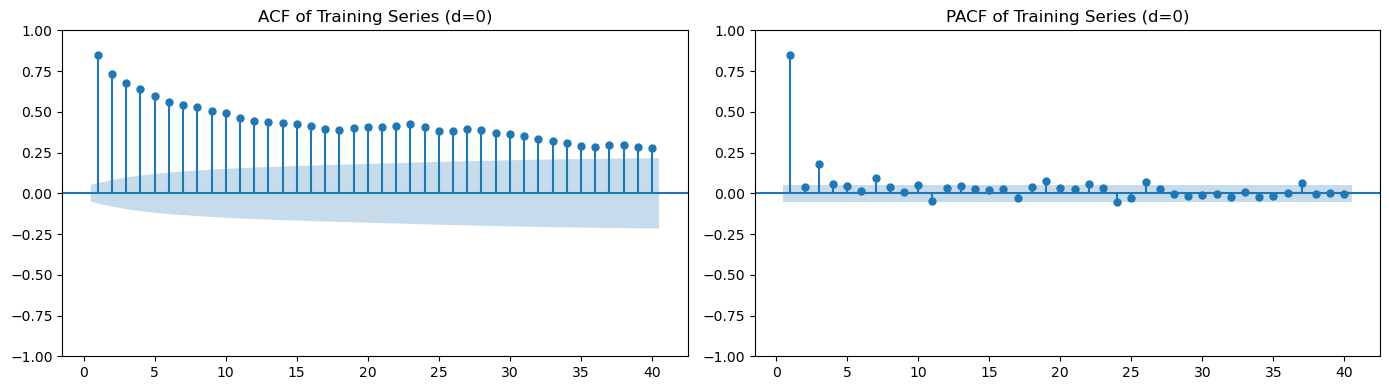

C:\Users\Dell\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\Dell\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'



In-sample Information Criteria (Training Period):


,order,AIC,BIC
0,"(2, 0, 2)",14718.613625,14750.125949
1,"(3, 0, 0)",14733.553510,14759.813779
2,"(1, 0, 1)",14769.105755,14790.113971
3,"(2, 0, 0)",14771.499253,14792.507469
4,"(1, 0, 0)",14773.129159,14788.885320
5,"(2, 0, 1)",14775.340316,14801.600585


C:\Users\Dell\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\Dell\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'



Walk-Forward Validation on 2024:


,order,MAE,RMSE
0,"(2, 0, 2)",24.007797,37.940709
1,"(3, 0, 0)",24.039120,37.826725
2,"(1, 0, 1)",24.415831,37.707612
3,"(2, 0, 0)",24.536640,37.978636
4,"(1, 0, 0)",24.736916,38.418165
5,"(2, 0, 1)",24.750260,38.683935



Frozen ARIMA Order: (2, 0, 2)


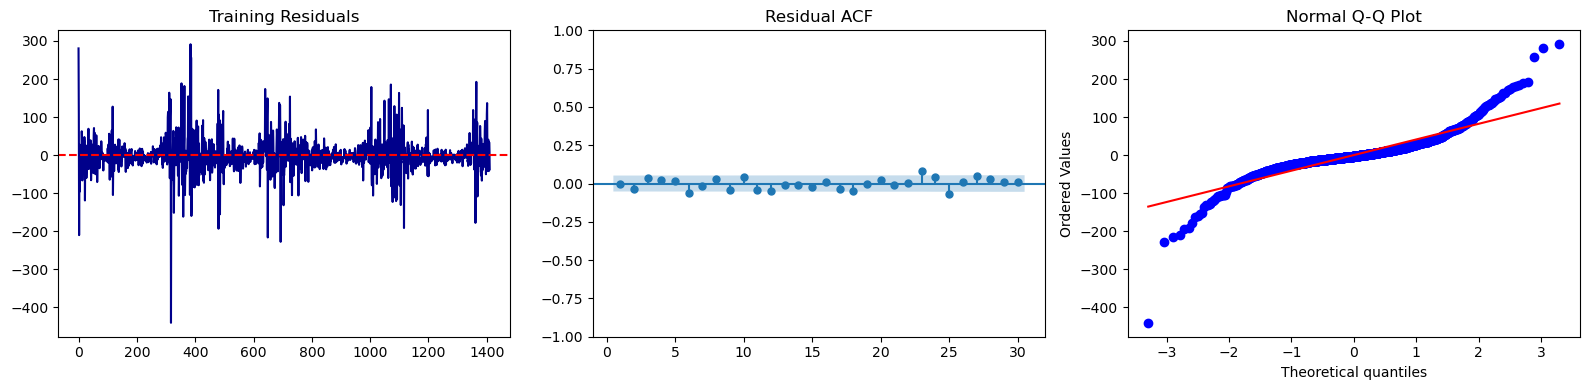


Ljung-Box Test on Model Residuals:


,lb_stat,lb_pvalue
10,16.931891,0.075885
20,30.589038,0.060855



Final Untouched 2025 Test Metrics for ARIMA(2, 0, 2):
MAE:  21.768 µg/m³
RMSE: 32.803 µg/m³
R²:   0.8304


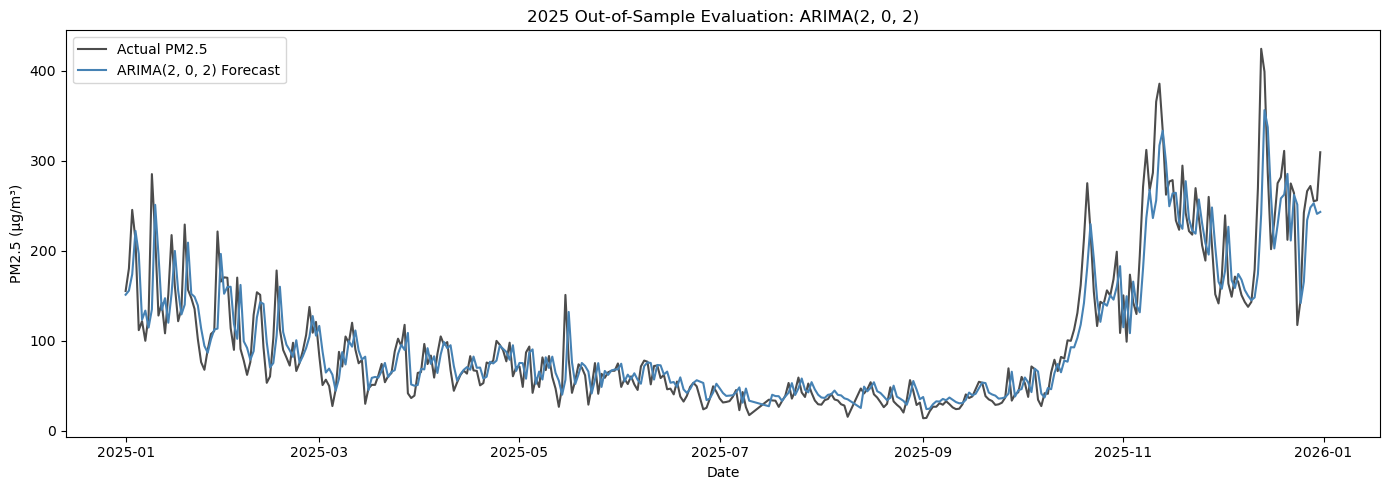

In [37]:
# %% [markdown]
# # Notebook 3: Classical Time Series Analysis & Leakage-Safe ARIMA Modeling

# %%
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller

plot_dir = "../plots" if os.path.exists("../plots") or os.path.exists("..") else "plots"
table_dir = "../results/tables" if os.path.exists("../results") or os.path.exists("..") else "results/tables"
os.makedirs(plot_dir, exist_ok=True)
os.makedirs(table_dir, exist_ok=True)

# %%
# 1. Load data & set strict chronological splits
candidates = [
    "../data/processed/delhi_pollution_weather_daily_2020_2025.csv",
    "data/processed/delhi_pollution_weather_daily_2020_2025.csv",
    "delhi_pollution_weather_daily_2020_2025.csv"
]
df = pd.read_csv(next(p for p in candidates if os.path.exists(p)))
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

# Split strictly chronologically
train = df[(df["Date"] >= "2020-01-01") & (df["Date"] < "2024-01-01")].copy()
val = df[(df["Date"] >= "2024-01-01") & (df["Date"] < "2025-01-01")].copy()
test = df[(df["Date"] >= "2025-01-01") & (df["Date"] < "2026-01-01")].copy()

train_ts = train.set_index("Date")["PM2.5"].asfreq("D").astype(float)
val_ts = val.set_index("Date")["PM2.5"].asfreq("D").astype(float)
test_ts = test.set_index("Date")["PM2.5"].asfreq("D").astype(float)

train_observed = train_ts.dropna()
print(f"Training count: {len(train_observed)} | Validation count: {len(val_ts)} | Test count: {len(test_ts)}")

# %%
# 2. Augmented Dickey-Fuller (ADF) Test (Training Set Only)
adf_res = adfuller(train_observed)
print("=== Augmented Dickey-Fuller Test (2020-2023) ===")
print(f"ADF Statistic: {adf_res[0]:.4f}")
print(f"p-value:       {adf_res[1]:.4f}")
for k, v in adf_res[4].items():
    print(f"Critical value {k}: {v:.4f}")

# Stationarity decision:
if adf_res[1] < 0.05:
    print("Decision: p < 0.05, reject H0. Set d=0.")
    d = 0
    analysis_series = train_observed.copy()
else:
    print("Decision: p >= 0.05, cannot reject H0. Differencing required. Set d=1.")
    d = 1
    analysis_series = train_observed.diff().dropna()

# %%
# 3. ACF and PACF Plots (Training Data Only)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(analysis_series.to_numpy(), lags=40, ax=axes[0], zero=False)
axes[0].set_title(f"ACF of Training Series (d={d})")

plot_pacf(analysis_series.to_numpy(), lags=40, ax=axes[1], zero=False, method="ywm")
axes[1].set_title(f"PACF of Training Series (d={d})")
plt.tight_layout()
plt.savefig(os.path.join(plot_dir, "05_arima_acf_pacf.png"), dpi=300)
plt.show()

# %%
# 4. In-Sample AIC/BIC Model Identification
candidate_orders = [
    (1, d, 0),
    (2, d, 0),
    (3, d, 0),
    (1, d, 1),
    (2, d, 1),
    (2, d, 2)
]

# Pass as raw contiguous floats to eliminate frequency warnings
train_vals = list(train_observed.values)
aic_bic_records = []
for order in candidate_orders:
    fit_m = ARIMA(train_vals, order=order).fit()
    aic_bic_records.append({"order": str(order), "AIC": fit_m.aic, "BIC": fit_m.bic})

aic_bic_table = pd.DataFrame(aic_bic_records).sort_values("AIC").reset_index(drop=True)
print("\nIn-sample Information Criteria (Training Period):")
display(aic_bic_table)

# %%
# 5. Walk-Forward Validation on 2024
def walk_forward_arima(history_series, future_series, order):
    """
    Simulates operational 1-step walk-forward forecasting.
    Maintains clean numeric array internally to eliminate statsmodels frequency warnings.
    """
    history = list(history_series.dropna().values)
    dates, actuals, predictions = [], [], []
    
    current_model = ARIMA(history, order=order).fit()
    
    for date, actual in future_series.items():
        fc = current_model.forecast(steps=1)
        pred_val = float(fc[0])
        
        dates.append(date)
        actuals.append(actual)
        predictions.append(pred_val)
        
        if pd.notna(actual):
            history.append(actual)
            current_model = current_model.append([actual], refit=False)
            
    return pd.DataFrame({"Actual": actuals, "Predicted": predictions}, index=dates)

val_eval_list = []
for order in candidate_orders:
    val_preds = walk_forward_arima(train_observed, val_ts, order=order)
    valid_pts = val_preds.dropna()
    mae = mean_absolute_error(valid_pts["Actual"], valid_pts["Predicted"])
    rmse = np.sqrt(mean_squared_error(valid_pts["Actual"], valid_pts["Predicted"]))
    val_eval_list.append({"order": order, "MAE": mae, "RMSE": rmse})

val_results_df = pd.DataFrame(val_eval_list).sort_values("MAE").reset_index(drop=True)
print("\nWalk-Forward Validation on 2024:")
display(val_results_df)

# Freeze the best performing order on the 2024 validation set
best_order = val_results_df.iloc[0]["order"]
print(f"\nFrozen ARIMA Order: {best_order}")

# %%
# 6. Residual Diagnostics for the Frozen Specification
best_fit = ARIMA(train_vals, order=best_order).fit()
residuals = pd.Series(best_fit.resid)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(residuals, color="darkblue")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Training Residuals")

plot_acf(residuals.dropna().to_numpy(), lags=30, ax=axes[1], zero=False)
axes[1].set_title("Residual ACF")

stats.probplot(residuals.dropna(), dist="norm", plot=axes[2])
axes[2].set_title("Normal Q-Q Plot")
plt.tight_layout()
plt.savefig(os.path.join(plot_dir, "06_arima_residual_diagnostics.png"), dpi=300)
plt.show()

# Ljung-Box test for white noise
lb_res = acorr_ljungbox(residuals, lags=[10, 20], return_df=True)
print("\nLjung-Box Test on Model Residuals:")
display(lb_res)

# %%
# 7. Final Untouched Evaluation on 2025 Test Set
# Combine 2020-2024 history for the final walk-forward pass
train_val_combined = pd.concat([train_ts, val_ts]).dropna()

test_preds = walk_forward_arima(train_val_combined, test_ts, order=best_order)
test_valid = test_preds.dropna()

arima_test_mae = mean_absolute_error(test_valid["Actual"], test_valid["Predicted"])
arima_test_rmse = np.sqrt(mean_squared_error(test_valid["Actual"], test_valid["Predicted"]))
arima_test_r2 = r2_score(test_valid["Actual"], test_valid["Predicted"])

print(f"\nFinal Untouched 2025 Test Metrics for ARIMA{best_order}:")
print(f"MAE:  {arima_test_mae:.3f} µg/m³")
print(f"RMSE: {arima_test_rmse:.3f} µg/m³")
print(f"R²:   {arima_test_r2:.4f}")

# %%
# 8. Plot 2025 Forecast vs Actual
plt.figure(figsize=(14, 5))
plt.plot(test_valid.index, test_valid["Actual"], label="Actual PM2.5", color="black", alpha=0.7)
plt.plot(test_valid.index, test_valid["Predicted"], label=f"ARIMA{best_order} Forecast", color="steelblue")
plt.title(f"2025 Out-of-Sample Evaluation: ARIMA{best_order}")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(plot_dir, "07_arima_2025_test_forecast.png"), dpi=300)
plt.show()

# Save metrics for cross-model benchmarking
arima_export = pd.DataFrame([{
    "Model": f"ARIMA{best_order}",
    "MAE": arima_test_mae,
    "RMSE": arima_test_rmse,
    "R2": arima_test_r2
}])
arima_export.to_csv(os.path.join(table_dir, "arima_test_metrics.csv"), index=False)